# Week 8: Evaluation Expansion
- Compute metrics beyond $R^2$: MAE and MdAPE
- Summarize Insights: Which price bands perform better?

Setup

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.impute import SimpleImputer
from lightgbm import LGBMRegressor
from sklearn.linear_model import RidgeCV


# Validation
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

In [4]:
# Load Dataset
df = pd.read_csv("/content/drive/MyDrive/IDX Data Science/with_features.csv")

/tmp/ipykernel_1607/3800747513.py:2: DtypeWarning: Columns (0,1,4,64,79,81,82,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/drive/MyDrive/IDX Data Science/with_features.csv")


In [5]:
test = df[df['FileDate'] == '2026-04-01']
print(f"Test set size: {len(test)}")
validation = df[df['FileDate'] == '2026-03-01']
print(f"Validation set size: {len(validation)}")
train = df[df['FileDate'] < '2026-03-01']
print(f"Train set size: {len(train)}")

print(f"Total Rows Check: {len(test) + len(validation) + len(train)}")

Test set size: 15225
Validation set size: 14118
Train set size: 349995
Total Rows Check: 379338


In [6]:
# set outlier cutoffs based on the training set
lower_bound = train['ClosePrice'].quantile(0.05)
upper_bound = train['ClosePrice'].quantile(0.995)
print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")

Lower bound: 365000.0
Upper bound: 8150554.99999944


In [7]:
cat_cols = ['City', 'CountyOrParish', 'DistrictName']
num_cols = ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Stories',
                'BedBathRatio', 'LotAreaRatio', 'AgeOfProperty', 'RelativeSize']
# create new copies of train, test, and validation
train = train[(train['ClosePrice'] > lower_bound) & (train['ClosePrice'] < upper_bound)]
validation = validation[(validation['ClosePrice'] > lower_bound) & (validation['ClosePrice'] < upper_bound)]
test = test[(test['ClosePrice'] > lower_bound) & (test['ClosePrice'] < upper_bound)]

# keep feature columns
train = train[cat_cols + num_cols + ['ClosePrice']]
validation = validation[cat_cols + num_cols + ['ClosePrice']]
test = test[cat_cols + num_cols + ['ClosePrice']]

In [8]:
# separate X's and Y for data sets
Y_train = train['ClosePrice'].copy()
X_train = train[num_cols + cat_cols].copy()

Y_val = validation['ClosePrice'].copy()
X_val = validation[num_cols + cat_cols].copy()

X_train_val = pd.concat([X_train, X_val], axis=0)
Y_train_val = pd.concat([Y_train, Y_val], axis=0)

Y_test = test['ClosePrice'].copy()
X_test = test[num_cols + cat_cols].copy()

In [9]:
# MdAPE
def median_absolute_percentage_error(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100
# function to evaluate different errors (R^2, MAE, MAPE, MdAPE)
def evaluate_predictions(y_true, y_pred, split_name="Validation"):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100  # Convert ratio to %
    mdape = median_absolute_percentage_error(y_true, y_pred)

    print(f"--- {split_name} Evaluation Metrics ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : ${mae:,.2f}")
    print(f"MAPE     : {mape:.2f}%")
    print(f"MdAPE    : {mdape:.2f}%\n")

In [13]:
# converting previous notebook code into functions
def prepare_train_val_test(X_train, Y_train, X_val, Y_val, X_test, Y_test):
    """Combines train + val splits and cleans +/- inf values across all feature sets."""
    X_train_val = pd.concat([X_train, X_val], axis=0).reset_index(drop=True).copy()
    Y_train_val = np.concatenate([np.asarray(Y_train).ravel(), np.asarray(Y_val).ravel()])

    X_test_clean = X_test.copy()
    Y_test_clean = np.asarray(Y_test).ravel()

    for df_split in [X_train_val, X_test_clean]:
        df_split.replace([np.inf, -np.inf], np.nan, inplace=True)

    return X_train_val, Y_train_val, X_test_clean, Y_test_clean


def build_preprocessor(num_cols, cat_cols, scale_num=False, random_state=42):
    """Builds a ColumnTransformer with optional StandardScaler for linear models."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_num:
        num_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(num_steps), num_cols),
            ("cat", TargetEncoder(random_state=random_state), cat_cols),
        ]
    )

In [19]:
def plot_diagnostics(actual_dollars, pred_dollars, model_name):
    """Generates side-by-side Actual vs. Predicted and Residual diagnostic plots."""
    residuals = actual_dollars - pred_dollars
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].scatter(actual_dollars, pred_dollars, alpha=0.3, s=10, color="mediumseagreen")
    lims = [
        min(actual_dollars.min(), pred_dollars.min()),
        max(actual_dollars.max(), pred_dollars.max()),
    ]
    axes[0].plot(lims, lims, "r--", label="Perfect prediction")
    axes[0].set_xlabel("Actual ClosePrice ($)")
    axes[0].set_ylabel("Predicted ClosePrice ($)")
    axes[0].set_title(f"{model_name} (Test): Actual vs. Predicted")
    axes[0].legend()

    axes[1].scatter(pred_dollars, residuals, alpha=0.3, s=10, color="lightcoral")
    axes[1].axhline(0, color="r", linestyle="--")
    axes[1].set_xlabel("Predicted ClosePrice ($)")
    axes[1].set_ylabel("Residual ($)")
    axes[1].set_title(f"{model_name} (Test): Residuals vs. Predicted")

    plt.tight_layout()
    plt.show()


def fit_and_evaluate_model(
    model_name,
    estimator,
    X_train_val,
    Y_train_val,
    X_test,
    Y_test,
    num_cols,
    cat_cols,
    scale_num=False,
    plot=True,
    random_state=42,
):
    """
    Wraps an estimator in a preprocessing Pipeline, fits on log(Y_train_val),
    evaluates in dollar space on X_test, and optionally plots diagnostics.
    """
    preprocessor = build_preprocessor(
        num_cols=num_cols,
        cat_cols=cat_cols,
        scale_num=scale_num,
        random_state=random_state,
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", estimator),
    ])

    # Fit in log space
    pipeline.fit(X_train_val, np.log(Y_train_val))

    # Predict and transform back to dollars
    test_pred_dollars = np.exp(pipeline.predict(X_test))
    test_actual_dollars = np.asarray(Y_test).ravel()

    # Core metrics
    r2 = r2_score(test_actual_dollars, test_pred_dollars)
    mae = mean_absolute_error(test_actual_dollars, test_pred_dollars)
    mape = np.mean(np.abs((test_actual_dollars - test_pred_dollars) / test_actual_dollars)) * 100
    mdape = np.median(np.abs((test_actual_dollars - test_pred_dollars) / test_actual_dollars)) * 100

    print(f"\n=== Final Test Set Evaluation: {model_name} ===")
    if "evaluate_predictions" in globals():
        evaluate_predictions(test_actual_dollars, test_pred_dollars, split_name=f"TEST SET ({model_name})")
    print(f"R2:    {r2:.4f}")
    print(f"MAE:   ${mae:,.2f}")
    print(f"MAPE:  {mape:.2f}%")
    print(f"MdAPE: {mdape:.2f}%")

    if plot:
        plot_diagnostics(test_actual_dollars, test_pred_dollars, model_name)

    return {
        "model_name": model_name,
        "pipeline": pipeline,
        "predictions": test_pred_dollars,
        "metrics": {
            "Model": model_name,
            "R2": r2,
            "MAE": mae,
            "MAPE (%)": mape,
            "MdAPE (%)": mdape,
        },
    }

## Model Metric Comparison

In [15]:
# 1. Prepare combined Train + Val and cleaned Test sets
X_train_val, Y_train_val, X_test_clean, Y_test_clean = prepare_train_val_test(
    X_train, Y_train, X_val, Y_val, X_test, Y_test
)

In [17]:

# 2. Define estimators & model-specific settings (plug in your tuned BEST_PARAMS)
models_config = {
    # LINEAR REGRESSION: ridge auto alpha & scaling numerical features
    "Linear Regression (Ridge)": {
        "estimator": RidgeCV(),
        "scale_num": True,
    },
    # DT: from 04_model comparison
    "Decision Tree": {
        "estimator": DecisionTreeRegressor(
            max_depth=15,
            min_samples_leaf=4,
            min_samples_split=10,
        ),
        "scale_num": False,
    },
    # RF: from 04_model comparison (runtime optimized)
    "Random Forest (sklearn)": {
        "estimator": RandomForestRegressor(
            n_estimators=100,
            max_depth=14,
            max_features=0.33,
            max_samples=0.7,
            min_samples_leaf=15,
            n_jobs=-1,
        ),
        "scale_num": False,
    },
    # LightGBM DT: parameters from 05_advanced_models
    "LightGBM (Decision Tree)": {
        "estimator": LGBMRegressor(
            boosting_type="gbdt",
            n_estimators=300,
            learning_rate=0.1,
            max_depth=8,
            num_leaves=31,
            n_jobs=-1,
        ),
        "scale_num": False,
    },
    # LightGBM RF: parameters from 05_advanced models (original)
    "LightGBM (Random Forest)": {
        "estimator": LGBMRegressor(
            boosting_type="rf",
            max_depth=12,
            num_leaves=255,
            n_estimators=200,
            learning_rate=0.1,
            #runtime settings
            subsample=0.7,
            subsample_freq=1,
            colsample_bytree=0.5,
            min_child_samples=20,
            n_jobs=-1,
        ),
        "scale_num": False,
    },
}

In [22]:
# run models and compute metrics
results = {}
metrics_list = []

for name, cfg in models_config.items():
    res = fit_and_evaluate_model(
        model_name=name,
        estimator=cfg["estimator"],
        X_train_val=X_train_val,
        Y_train_val=Y_train_val,
        X_test=X_test_clean,
        Y_test=Y_test_clean,
        num_cols=num_cols,
        cat_cols=cat_cols,
        scale_num=cfg["scale_num"],
        plot=False)
    results[name] = res
    metrics_list.append(res["metrics"])


=== Final Test Set Evaluation: Linear Regression (Ridge) ===
--- TEST SET (Linear Regression (Ridge)) Evaluation Metrics ---
R² Score : 0.6390
MAE      : $247,660.13
MAPE     : 16.74%
MdAPE    : 12.07%

R2:    0.6390
MAE:   $247,660.13
MAPE:  16.74%
MdAPE: 12.07%

=== Final Test Set Evaluation: Decision Tree ===
--- TEST SET (Decision Tree) Evaluation Metrics ---
R² Score : 0.8273
MAE      : $206,908.59
MAPE     : 14.15%
MdAPE    : 9.49%

R2:    0.8273
MAE:   $206,908.59
MAPE:  14.15%
MdAPE: 9.49%

=== Final Test Set Evaluation: Random Forest (sklearn) ===
--- TEST SET (Random Forest (sklearn)) Evaluation Metrics ---
R² Score : 0.8458
MAE      : $194,634.32
MAPE     : 13.27%
MdAPE    : 9.11%

R2:    0.8458
MAE:   $194,634.32
MAPE:  13.27%
MdAPE: 9.11%
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.090067 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2061
[LightGBM] [Info] Number of data points i

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



=== Final Test Set Evaluation: LightGBM (Decision Tree) ===
--- TEST SET (LightGBM (Decision Tree)) Evaluation Metrics ---
R² Score : 0.8571
MAE      : $190,005.28
MAPE     : 13.09%
MdAPE    : 9.10%

R2:    0.8571
MAE:   $190,005.28
MAPE:  13.09%
MdAPE: 9.10%
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.041656 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2061
[LightGBM] [Info] Number of data points in the train set: 343415, number of used features: 13
[LightGBM] [Info] Start training from score 13.824523


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



=== Final Test Set Evaluation: LightGBM (Random Forest) ===
--- TEST SET (LightGBM (Random Forest)) Evaluation Metrics ---
R² Score : 0.7913
MAE      : $228,055.64
MAPE     : 15.42%
MdAPE    : 11.32%

R2:    0.7913
MAE:   $228,055.64
MAPE:  15.42%
MdAPE: 11.32%


,Model,R2,MAE,MAPE (%),MdAPE (%)
0,LightGBM (Decision Tree),0.857106,190005.280736,13.088529,9.101826
1,Random Forest (sklearn),0.845781,194634.315249,13.269795,9.105596
2,Decision Tree,0.827299,206908.587595,14.146999,9.487972
3,LightGBM (Random Forest),0.791250,228055.640207,15.416508,11.324362
4,Linear Regression (Ridge),0.639000,247660.128998,16.736938,12.072217


In [23]:
# 4. Side-by-side summary table
summary_df = pd.DataFrame(metrics_list).sort_values("MAE").reset_index(drop=True)
display(summary_df)

,Model,R2,MAE,MAPE (%),MdAPE (%)
0,LightGBM (Decision Tree),0.857106,190005.280736,13.088529,9.101826
1,Random Forest (sklearn),0.845781,194634.315249,13.269795,9.105596
2,Decision Tree,0.827299,206908.587595,14.146999,9.487972
3,LightGBM (Random Forest),0.791250,228055.640207,15.416508,11.324362
4,Linear Regression (Ridge),0.639000,247660.128998,16.736938,12.072217


- With my features, the gradient boosted decision tree performed the best across metrics, followed by the random forest model without gradient boosting


## Price Band Comparison

- Dividing using percentiles into equal size bins
- evaluating possible systematic bias: Median Signed Bias/MdSPE
  - MdSPE < 0: over prediction
    - "For a typical home in that band, the model overpredicts __% of the actual sale price"
  - MdSPE > 0: under prediction
    - "For a typical home in that band, the model underpredicts __% of the actual sale price"

Setup

In [25]:
# format millions into more readable format
def _format_currency_short(val):
    if val >= 1_000_000:
        return f"${val / 1e6:.2f}M"
    return f"${val / 1e3:,.0f}k"

# ONLY PASS IN Y_TRAIN OR Y_TRAIN_VAL
def get_quantile_price_bands(Y_reference, q=5, custom_labels=None):
    """
    Y_reference : Training target variable values (array-like_)
    q: Number of quantiles (e.g., 4=quartiles, 5=quintiles, 10=deciles).
    custom_labels : list of str, optional
        Optional override labels matching the resulting number of bins.
    """
    y_ref = np.asarray(Y_reference).ravel()

    # Compute exact quantile cutoffs
    _, bins = pd.qcut(y_ref, q=q, retbins=True, duplicates="drop")

    # Extend outer boundaries to [0, inf) so test extremes never become NaN
    raw_lower, raw_upper = bins[0], bins[-1]
    bins[0] = 0.0
    bins[-1] = np.inf

    if custom_labels is not None:
        if len(custom_labels) != len(bins) - 1:
            raise ValueError(
                f"Expected {len(bins) - 1} labels for {len(bins) - 1} bins, got {len(custom_labels)}."
            )
        return bins, custom_labels

    labels = []
    n_bins = len(bins) - 1
    for i in range(n_bins):
        low_str = _format_currency_short(bins[i])
        high_str = _format_currency_short(bins[i + 1])

        if i == 0:
            labels.append(f"Q1 (< {high_str})")
        elif i == n_bins - 1:
            labels.append(f"Q{i+1} ({low_str}+)")
        else:
            labels.append(f"Q{i+1} ({low_str}–{high_str})")

    return bins, labels

In [26]:
def evaluate_models_by_price_band(results_dict, actual_dollars, bins, labels):
    """
    Evaluates all fitted models in `results_dict` across actual price bands.
    Returns:
      - long_df: tidy DataFrame with Model, Price_Band, Count, MAE, MAPE, MdAPE, Bias_Pct
      - pivots: dict of wide comparison tables ('MdAPE (%)', 'MAE ($)', 'Bias (%)')
    """
    actual_arr = np.asarray(actual_dollars).ravel()
    bands = pd.cut(actual_arr, bins=bins, labels=labels, right=False)

    records = []
    for model_name, res in results_dict.items():
        preds = np.asarray(res["predictions"]).ravel()
        df_eval = pd.DataFrame({
            "band": bands,
            "actual": actual_arr,
            "pred": preds,
        })
        df_eval["abs_err"] = np.abs(df_eval["actual"] - df_eval["pred"])
        df_eval["ape"] = (df_eval["abs_err"] / df_eval["actual"]) * 100
        df_eval["spe"] = ((df_eval["pred"] - df_eval["actual"]) / df_eval["actual"]) * 100

        for band_label, grp in df_eval.groupby("band", observed=False):
            if len(grp) == 0:
                continue
            records.append({
                "Model": model_name,
                "Price_Band": band_label,
                "Count": len(grp),
                "MAE ($)": grp["abs_err"].mean(),
                "MAPE (%)": grp["ape"].mean(),
                "MdAPE (%)": grp["ape"].median(),
                "Median Bias (%)": grp["spe"].median(),  # negative = underpredicting
            })

    long_df = pd.DataFrame(records)

    pivots = {
        metric: long_df.pivot(index="Price_Band", columns="Model", values=metric)
        for metric in ["MdAPE (%)", "MAE ($)", "Median Bias (%)"]
    }
    return long_df, pivots

In [27]:
def plot_price_band_comparison(long_df, model_order=None):
    """Plots MdAPE (%) and Median Bias (%) across price bands for all models."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # 1. Accuracy across bands (MdAPE)
    sns.barplot(
        data=long_df,
        x="Price_Band",
        y="MdAPE (%)",
        hue="Model",
        hue_order=model_order,
        ax=axes[0],
    )
    axes[0].set_title("Median Percentage Error (MdAPE) by Price Band")
    axes[0].set_xlabel("Actual ClosePrice Band")
    axes[0].set_ylabel("MdAPE (%) — Lower is Better")
    axes[0].tick_params(axis="x", rotation=25)
    axes[0].legend(title="Model", fontsize=8)

    # 2. Directional Bias across bands (Under- vs Over-prediction)
    sns.barplot(
        data=long_df,
        x="Price_Band",
        y="Median Bias (%)",
        hue="Model",
        hue_order=model_order,
        ax=axes[1],
    )
    axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[1].set_title("Median Signed Bias (%) by Price Band")
    axes[1].set_xlabel("Actual ClosePrice Band")
    axes[1].set_ylabel("Median Bias (%) [0 = Unbiased]")
    axes[1].tick_params(axis="x", rotation=25)
    axes[1].get_legend().remove()

    plt.tight_layout()
    plt.show()

Evaluation

In [28]:
# get bins and labels for quantile-divided price bands
bins, labels = get_quantile_price_bands(Y_train_val, q=5)

# compute metrics across 5 models
long_band_df, pivot_tables = evaluate_models_by_price_band(
    results_dict=results,
    actual_dollars=Y_test_clean,
    bins=bins,
    labels=labels,
)

In [29]:
#Comparison
print("=== MdAPE (%) by Price Band ===")
display(pivot_tables["MdAPE (%)"].round(2))

print("\n=== MAE ($) by Price Band ===")
display(pivot_tables["MAE ($)"].style.format("${:,.0f}"))

print("\n=== Median Bias (%) by Price Band (Negative = Underpredicting) ===")
display(pivot_tables["Median Bias (%)"].round(2))

=== MdAPE (%) by Price Band ===


Model,Decision Tree,LightGBM (Decision Tree),LightGBM (Random Forest),Linear Regression (Ridge),Random Forest (sklearn)
Price_Band,,,,,
Q1 (< $605k),7.07,7.25,11.75,10.70,7.02
Q2 ($605k–$800k),7.27,7.05,7.70,9.90,6.91
Q3 ($800k–$1.07M),8.14,7.90,8.62,9.81,7.98
Q4 ($1.07M–$1.64M),11.38,10.78,11.98,12.55,10.84
Q5 ($1.64M+),15.22,14.07,18.53,19.58,14.55



=== MAE ($) by Price Band ===


Model,Decision Tree,LightGBM (Decision Tree),LightGBM (Random Forest),Linear Regression (Ridge),Random Forest (sklearn)
Price_Band,,,,,
Q1 (< $605k),"$61,650","$59,276","$80,617","$84,498","$60,103"
Q2 ($605k–$800k),"$81,093","$75,597","$84,616","$100,810","$75,153"
Q3 ($800k–$1.07M),"$109,081","$99,689","$108,168","$121,889","$100,181"
Q4 ($1.07M–$1.64M),"$198,068","$184,235","$194,750","$203,720","$186,540"
Q5 ($1.64M+),"$542,837","$493,351","$624,006","$676,232","$511,678"



=== Median Bias (%) by Price Band (Negative = Underpredicting) ===


Model,Decision Tree,LightGBM (Decision Tree),LightGBM (Random Forest),Linear Regression (Ridge),Random Forest (sklearn)
Price_Band,,,,,
Q1 (< $605k),2.76,3.44,11.10,7.23,3.76
Q2 ($605k–$800k),0.92,0.56,3.44,2.18,1.15
Q3 ($800k–$1.07M),-1.57,-0.91,0.30,0.51,-0.89
Q4 ($1.07M–$1.64M),-4.49,-4.78,-5.55,-5.25,-4.52
Q5 ($1.64M+),-9.28,-8.96,-16.20,-14.45,-10.09


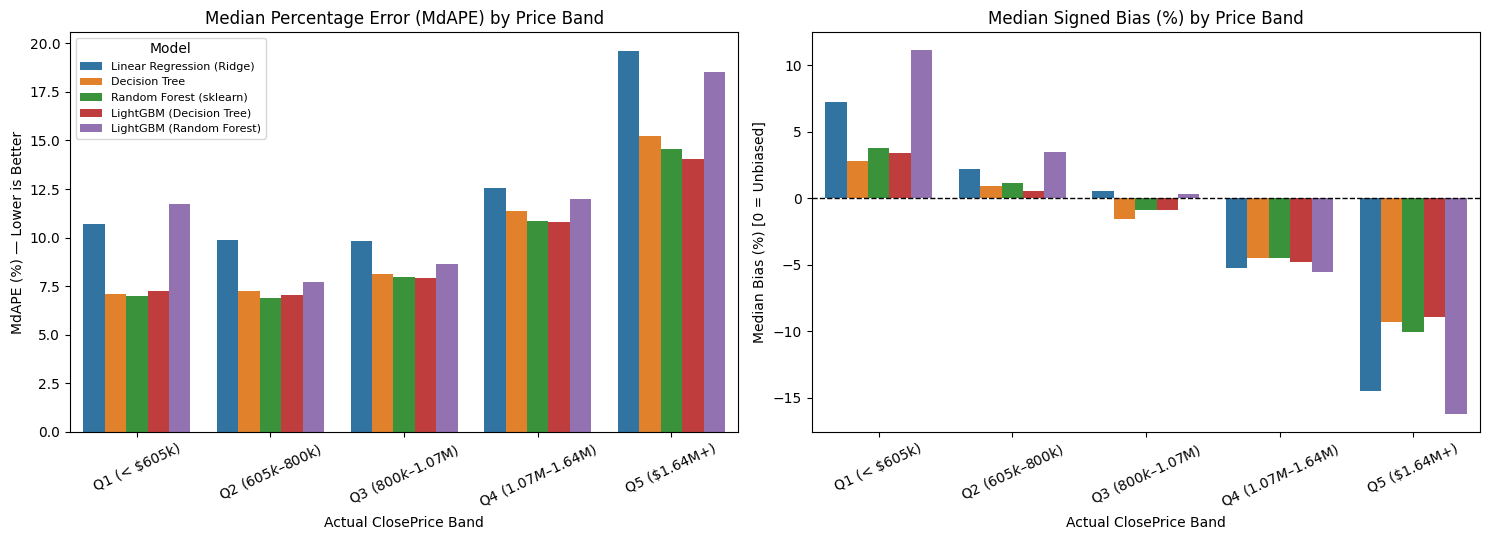

In [31]:
# Visuzlie
plot_price_band_comparison(long_band_df, model_order=list(results.keys()))

- across models, we see an increase in MdApe with price bands
  - in the lowest and highest price bands, the linear regression model and gradient-boosted RF model diverge the most
- models tend to perform better in the middle-range price bands in terms of bias
  - mostly tend to underpredict for Q1 and Q1, and overpredict for Q3, Q4, and Q5
  - the linear gradient-boosted RF models also show the greates divergence in median bias

### Creating Summary Table

In [35]:
import pandas as pd

# Combine the pivot tables into a single DataFrame by melting and merging them
mdape_df = pivot_tables["MdAPE (%)"].reset_index().melt(id_vars="Price_Band", value_name="MdAPE (%)")
mae_df = pivot_tables["MAE ($)"].reset_index().melt(id_vars="Price_Band", value_name="MAE ($)")
bias_df = pivot_tables["Median Bias (%)"].reset_index().melt(id_vars="Price_Band", value_name="Median Bias (%)")

# Merge them on Price_Band and Model
combined_summary = pd.merge(mdape_df, mae_df, on=["Price_Band", "Model"])
combined_summary = pd.merge(combined_summary, bias_df, on=["Price_Band", "Model"])

# Round and clean for final presentation
combined_summary["MdAPE (%)"] = combined_summary["MdAPE (%)"].round(2)
combined_summary["MAE ($)"] = combined_summary["MAE ($)"].round(2)
combined_summary["Median Bias (%)"] = combined_summary["Median Bias (%)"].round(2)

# Display the combined DataFrame
display(combined_summary)

,Price_Band,Model,MdAPE (%),MAE ($),Median Bias (%)
0,Q1 (< $605k),Decision Tree,7.07,61649.91,2.76
1,Q2 ($605k–$800k),Decision Tree,7.27,81092.80,0.92
2,Q3 ($800k–$1.07M),Decision Tree,8.14,109081.42,-1.57
3,Q4 ($1.07M–$1.64M),Decision Tree,11.38,198068.20,-4.49
4,Q5 ($1.64M+),Decision Tree,15.22,542837.50,-9.28
5,Q1 (< $605k),LightGBM (Decision Tree),7.25,59276.02,3.44
6,Q2 ($605k–$800k),LightGBM (Decision Tree),7.05,75596.60,0.56
7,Q3 ($800k–$1.07M),LightGBM (Decision Tree),7.90,99688.95,-0.91
8,Q4 ($1.07M–$1.64M),LightGBM (Decision Tree),10.78,184235.12,-4.78
9,Q5 ($1.64M+),LightGBM (Decision Tree),14.07,493351.36,-8.96


In [37]:
# REORDERING COLUMNS
columns_ordered = ["Model", "Price_Band", "MdAPE (%)", "MAE ($)", "Median Bias (%)"]
combined_summary = combined_summary[columns_ordered]

# Save the reordered DataFrame to CSV
combined_summary.to_csv("/content/drive/MyDrive/IDX Data Science/price_band_metrics_summary.csv", index=False)
print("Saved reordered summary to 'price_band_metrics_summary.csv'")

# Display the updated DataFrame
display(combined_summary.head(10))

Saved reordered summary to 'price_band_metrics_summary.csv'


,Model,Price_Band,MdAPE (%),MAE ($),Median Bias (%)
0,Decision Tree,Q1 (< $605k),7.07,61649.91,2.76
1,Decision Tree,Q2 ($605k–$800k),7.27,81092.80,0.92
2,Decision Tree,Q3 ($800k–$1.07M),8.14,109081.42,-1.57
3,Decision Tree,Q4 ($1.07M–$1.64M),11.38,198068.20,-4.49
4,Decision Tree,Q5 ($1.64M+),15.22,542837.50,-9.28
5,LightGBM (Decision Tree),Q1 (< $605k),7.25,59276.02,3.44
6,LightGBM (Decision Tree),Q2 ($605k–$800k),7.05,75596.60,0.56
7,LightGBM (Decision Tree),Q3 ($800k–$1.07M),7.90,99688.95,-0.91
8,LightGBM (Decision Tree),Q4 ($1.07M–$1.64M),10.78,184235.12,-4.78
9,LightGBM (Decision Tree),Q5 ($1.64M+),14.07,493351.36,-8.96
